# Parcial práctico · Corte 3 — Análisis temporal, visualización y optimización

**Electiva · Ciencia de Datos · CORHUILA 2026-B** · Docente: Jesús Ariel González Bonilla
**Estudiante:** Julián Andrés Solano Ledesma · **Modalidad:** individual · **Valor:** 5,0

**Caso:** Spotify — capacidad de streaming y curaduría regional, el mismo caso del curso.

| Problema | Tema | Puntos |
|---|---|---:|
| 1 | Serie de tiempo: fecha como índice, `resample`, media móvil, tendencia y estacionalidad | 1,5 |
| 2 | Visualización: gráfico correcto para 3 preguntas y corrección de un gráfico engañoso | 1,5 |
| 3 | Optimización SQL, 2 medidas DAX, medida frente a columna calculada y texto en inglés | 2,0 |

El cuaderno se ejecuta desde la carpeta `15-week/` del repositorio. Lee la serie de la Semana 11, la base del caso de la Semana 10 y la tabla de eventos de la Semana 14.

## Preparar el entorno

Herramientas: pandas [1] para la serie y las tablas, Matplotlib [2] para los gráficos y SQLite [3] para las consultas.

In [1]:
import sqlite3, statistics, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "14-week" / "02-optional-activity"))
import optimizacion_sql as O14      # generador de la tabla de 2 000 000 de eventos (Semana 14)
%matplotlib inline

AZUL, NARANJA, GRIS, ROJO = "#2a78d6", "#eb6834", "#8a8984", "#d03b3b"
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e7e6e2", "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9.5, "figure.facecolor": FONDO, "axes.facecolor": FONDO,
                     "axes.titleweight": "bold", "axes.titlesize": 10.5, "axes.titlelocation": "left"})

def limpiar(ax, eje="y"):
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(REJILLA)
    ax.tick_params(length=0, colors=TINTA2)
    getattr(ax, f"{eje}axis").grid(True, color=REJILLA)
    ax.set_axisbelow(True)

def es(v, d=1):
    return f"{v:,.{d}f}".replace(",", " ").replace(".", ",")

## Problema 1 · Serie de tiempo (1,5)

**Serie:** visitas diarias al artículo *Spotify* de Wikipedia en inglés, tomadas de la API de Wikimedia [4], como aproximación del interés del público. Se agrega **por trimestre** y se calcula una media móvil para separar la tendencia de la estacionalidad [5], [6].

In [2]:
# 1) Carga con la fecha como índice
serie = pd.read_csv(RAIZ / "11-week" / "02-optional-activity" / "datos" / "pageviews_spotify_diario.csv",
                    parse_dates=["fecha"])            # texto -> fecha
serie = serie.set_index("fecha")["visitas"]           # la fecha pasa a ser el índice
print(type(serie.index).__name__, "·", len(serie), "días ·", serie.index.min().date(), "a", serie.index.max().date(),
      "· nulos:", int(serie.isna().sum()))

# 2) Agregación por trimestre (resample) y 3) media móvil de 4 trimestres, centrada (2x4)
trim = serie.resample("QS").mean().round(1).to_frame("visitas_dia_prom")
trim["media_movil_2x4"] = trim["visitas_dia_prom"].rolling(4).mean().rolling(2).mean().shift(-2).round(1)
trim["trimestre"] = trim.index.year.astype(str) + "-T" + trim.index.quarter.astype(str)
trim = trim.set_index("trimestre")
trim.tail(8)

DatetimeIndex · 3926 días · 2016-01-01 a 2026-09-30 · nulos: 0


,visitas_dia_prom,media_movil_2x4
trimestre,,
2024-T4,4938.8,4835.4
2025-T1,5435.7,4545.0
2025-T2,3534.3,4472.9
2025-T3,4133.8,4235.5
2025-T4,4637.1,4084.5
2026-T1,3838.2,3966.1
2026-T2,3923.7,NaN
2026-T3,2797.2,NaN


In [3]:
# 4) Tendencia y estacionalidad
mm = trim["media_movil_2x4"].dropna()
print(f"Tendencia: {es(mm.iloc[0], 0)} ({mm.index[0]}) -> máximo {es(mm.max(), 0)} ({mm.idxmax()}) -> {es(mm.iloc[-1], 0)} ({mm.index[-1]})")

ratio = (trim["visitas_dia_prom"] / trim["media_movil_2x4"]).dropna()
q = ratio.index.str[-1]
est = pd.DataFrame({"efecto_pct": ((ratio.groupby(q).median() / ratio.groupby(q).median().mean() - 1) * 100).round(1),
                    "años_sobre_tendencia": ratio.gt(1).groupby(q).sum(),
                    "años_medidos": ratio.groupby(q).count()})
est.index = ["T1 (ene–mar)", "T2 (abr–jun)", "T3 (jul–sep)", "T4 (oct–dic)"]
est

Tendencia: 3 670 (2016-T3) -> máximo 9 658 (2022-T3) -> 3 966 (2026-T1)


,efecto_pct,años_sobre_tendencia,años_medidos
T1 (ene–mar),5.6,8,10
T2 (abr–jun),-2.9,4,9
T3 (jul–sep),-6.9,2,10
T4 (oct–dic),4.2,7,10


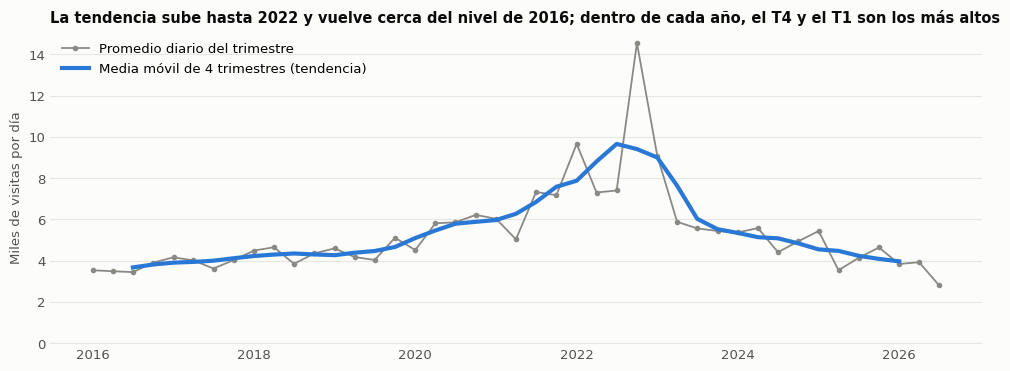

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = pd.PeriodIndex(trim.index.str.replace("-T", "Q"), freq="Q").to_timestamp()
ax.plot(x, trim["visitas_dia_prom"] / 1000, color=GRIS, lw=1.3, marker="o", ms=3, label="Promedio diario del trimestre")
ax.plot(x, trim["media_movil_2x4"] / 1000, color=AZUL, lw=3, label="Media móvil de 4 trimestres (tendencia)")
ax.set_ylim(0, None); ax.set_ylabel("Miles de visitas por día", color=TINTA2)
ax.legend(frameon=False, loc="upper left"); limpiar(ax)
ax.set_title("La tendencia sube hasta 2022 y vuelve cerca del nivel de 2016; dentro de cada año, el T4 y el T1 son los más altos", color=TINTA)
fig.tight_layout(); plt.show()

**Interpretación del Problema 1**

* **Carga:** `parse_dates` convierte el texto en fecha y `set_index` la vuelve índice (`DatetimeIndex`). Si la fecha quedara como texto, no se podría agregar ni ordenar por periodo [5].
* **`resample("QS").mean()`:** agrega la serie por trimestre [5]. Se usa el **promedio diario** del trimestre, porque los trimestres no tienen el mismo número de días.
* **Media móvil 2×4:** cuatro trimestres forman un año completo, así que los trimestres altos y bajos se compensan y queda la **tendencia**. Se centra (2×4) para que cada valor corresponda a un trimestre exacto [6].
* **Tendencia:** sube de **3 670** visitas diarias (2016-T3) a un máximo de **9 658** (2022-T3) y baja a **3 966** (2026-T1), cerca del nivel de 2016.
* **Estacionalidad:** el **T1** está típicamente un **+5,6 %** sobre la tendencia (8 de 10 años) y el **T4** un **+4,2 %** (7 de 10). El **T3** está un **−6,9 %** por debajo (solo 2 de 10 años sobre la tendencia) y el T2 un −2,9 %. El interés es alto en el cambio de año y bajo a mitad de año. Por trimestre la amplitud es menor que por mes, porque dentro de un trimestre se compensan meses altos y bajos (abril es alto, junio es bajo).
* **Para el caso:** conviene reforzar la capacidad en el T4 y el T1, y programar los mantenimientos en el T3.

## Problema 2 · Visualización (1,5)

### 2.1 Gráfico correcto para tres preguntas

El gráfico se elige según la pregunta, no según lo llamativo que sea [7]. Los datos de la comparación y de la proporción salen de la base del caso (dataset de Kaggle [8], Semana 10).

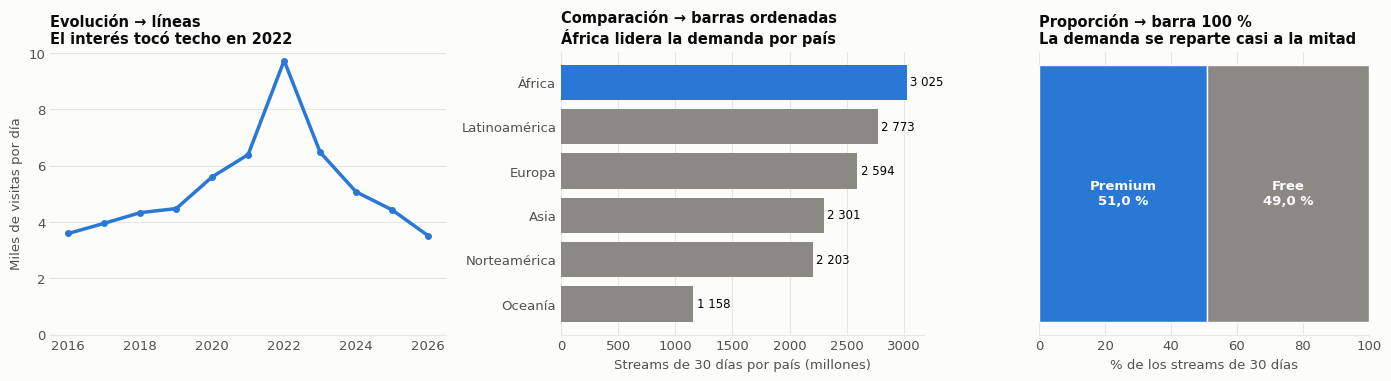

,region,streams_por_pais
0,Oceanía,1158.4
1,Norteamérica,2203.2
2,Asia,2300.9
3,Europa,2594.2
4,Latinoamérica,2772.9
5,África,3025.0


In [5]:
con_caso = sqlite3.connect(RAIZ / "10-week" / "02-optional-activity" / "datos" / "spotify.db")
region = pd.read_sql('''SELECT p.region, SUM(m.streams_30d_m) / COUNT(DISTINCT p.country_id) AS streams_por_pais
                        FROM metrica_streaming m JOIN pais p ON p.country_id = m.country_id
                        GROUP BY p.region ORDER BY streams_por_pais''', con_caso)
plan = pd.read_sql('''SELECT ps.nombre AS plan, SUM(m.streams_30d_m) AS streams
                      FROM metrica_streaming m JOIN plan_suscripcion ps ON ps.plan_id = m.plan_id
                      GROUP BY ps.nombre''', con_caso).set_index("plan")
plan["pct"] = (100 * plan["streams"] / plan["streams"].sum()).round(1)

anual = serie.resample("YS").mean()
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 3.9), gridspec_kw={"width_ratios": [1.2, 1.1, 1]})
# Evolución -> líneas
a1.plot(anual.index.year, anual / 1000, color=AZUL, lw=2.5, marker="o", ms=4)
a1.set_ylim(0, None); a1.set_ylabel("Miles de visitas por día", color=TINTA2); limpiar(a1)
a1.set_title("Evolución → líneas\nEl interés tocó techo en 2022", color=TINTA)
# Comparación -> barras horizontales ordenadas
a2.barh(region["region"], region["streams_por_pais"], color=[AZUL if v == region["streams_por_pais"].max() else GRIS for v in region["streams_por_pais"]])
for i, v in enumerate(region["streams_por_pais"]):
    a2.text(v + 30, i, es(v, 0), va="center", fontsize=8.5)
a2.set_xlabel("Streams de 30 días por país (millones)", color=TINTA2); limpiar(a2, "x")
a2.set_title("Comparación → barras ordenadas\nÁfrica lidera la demanda por país", color=TINTA)
# Proporción -> barra apilada al 100 % (2 categorías)
izq = 0
for nombre, color in [("Premium", AZUL), ("Free", GRIS)]:
    v = plan.loc[nombre, "pct"]
    a3.barh([0], [v], left=izq, color=color, edgecolor=FONDO, height=0.5)
    a3.text(izq + v / 2, 0, f"{nombre}\n{es(v)} %", ha="center", va="center", color="white", fontweight="bold")
    izq += v
a3.set_xlim(0, 100); a3.set_yticks([]); a3.set_xlabel("% de los streams de 30 días", color=TINTA2); limpiar(a3, "x")
a3.set_title("Proporción → barra 100 %\nLa demanda se reparte casi a la mitad", color=TINTA)
fig.tight_layout(); plt.show()
region.round(1)

**Justificación del Problema 2.1**

| Pregunta | Gráfico elegido | Por qué |
|---|---|---|
| **Evolución:** ¿cómo cambió el interés en Spotify de un año a otro? | **Líneas** | La línea muestra la continuidad en el tiempo y la dirección de la tendencia [7]. |
| **Comparación:** ¿qué región tiene más demanda reciente por país? | **Barras horizontales ordenadas** | Comparar longitudes sobre una escala común es más preciso que comparar ángulos o áreas [9]. El orden da el ranking de inmediato y la barra horizontal deja leer los nombres. |
| **Proporción:** ¿qué parte de la demanda es Premium? | **Barra apilada al 100 %** | Muestra partes de un total. Con 2 categorías una torta sería aceptable [7], pero la barra deja ver mejor que el reparto es casi mitad y mitad (51,0 % Premium frente a 49,0 % Free), porque los ángulos se comparan con menos precisión [9]. |

Cada gráfico lleva un título que dice la conclusión y un eje desde 0. En la evolución, el punto de 2026 promedia solo enero–septiembre, así que no es un año completo. En la comparación, África es en realidad un solo país (South Africa), así que su promedio por país es el de ese mercado.

### 2.2 Detectar y corregir un gráfico engañoso

El gráfico de la izquierda compara la participación Premium por región **con el eje truncado en 40 %**. El de la derecha es la corrección.

Oceanía 70.5 % frente a Asia 43.1 %: diferencia real 64%; la barra se ve 9.8 veces más alta; factor de mentira 13.9


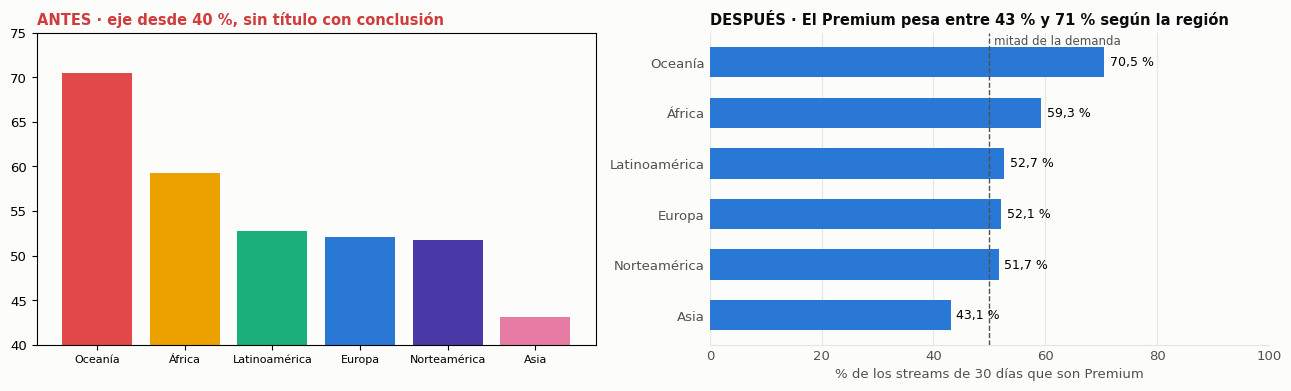

,region,pct_premium
0,Oceanía,70.5
1,África,59.3
2,Latinoamérica,52.7
3,Europa,52.1
4,Norteamérica,51.7
5,Asia,43.1


In [6]:
prem = pd.read_sql('''SELECT p.region,
                             100.0 * SUM(CASE WHEN ps.nombre = 'Premium' THEN m.streams_30d_m END) / SUM(m.streams_30d_m) AS pct_premium
                      FROM metrica_streaming m JOIN pais p ON p.country_id = m.country_id
                      JOIN plan_suscripcion ps ON ps.plan_id = m.plan_id
                      GROUP BY p.region ORDER BY pct_premium DESC''', con_caso).round(1)
con_caso.close()
alto, bajo, base = prem.iloc[0], prem.iloc[-1], 40
efecto_datos = (alto.pct_premium - bajo.pct_premium) / bajo.pct_premium
efecto_grafico = ((alto.pct_premium - base) - (bajo.pct_premium - base)) / (bajo.pct_premium - base)
factor = efecto_grafico / efecto_datos
print(f"{alto.region} {alto.pct_premium} % frente a {bajo.region} {bajo.pct_premium} %: diferencia real {efecto_datos:.0%}; "
      f"la barra se ve {(alto.pct_premium - base) / (bajo.pct_premium - base):.1f} veces más alta; factor de mentira {factor:.1f}")

fig, (m1, m2) = plt.subplots(1, 2, figsize=(13, 4))
m1.bar(prem["region"], prem["pct_premium"], color=["#e34948", "#eda100", "#1baf7a", "#2a78d6", "#4a3aa7", "#e87ba4"])
m1.set_ylim(base, 75); m1.tick_params(axis="x", labelsize=8)
m1.set_title("ANTES · eje desde 40 %, sin título con conclusión", color=ROJO)
m2.barh(prem["region"][::-1], prem["pct_premium"][::-1], color=AZUL, height=0.6)
for i, v in enumerate(prem["pct_premium"][::-1]):
    m2.text(v + 1, i, f"{es(v)} %", va="center", fontsize=9)
m2.axvline(50, color=TINTA2, ls="--", lw=1); m2.text(50.8, 5.35, "mitad de la demanda", fontsize=8.5, color=TINTA2)
m2.set_xlim(0, 100); m2.set_xlabel("% de los streams de 30 días que son Premium", color=TINTA2); limpiar(m2, "x")
m2.set_title("DESPUÉS · El Premium pesa entre 43 % y 71 % según la región", color=TINTA)
fig.tight_layout(); plt.show()
prem

**Error detectado y corrección (Problema 2.2)**

| | Antes | Después |
|---|---|---|
| **Escala** | Eje vertical **truncado en 40 %** | Eje desde **0 %** |
| **Color** | Un color distinto por región, sin significado | Un solo color: la región ya está escrita junto a la barra |
| **Título** | Describe la variable, no dice la conclusión | "El Premium pesa entre 43 % y 71 % según la región" |
| **Lectura** | Sin unidades ni valores | Valores en cada barra, eje con unidades y referencia del 50 % |

**Cuánto engaña.** Oceanía (70,5 %) tiene un 64 % más de participación Premium que Asia (43,1 %), pero con el eje en 40 % su barra se ve **9,8 veces** más alta. El **factor de mentira** de Tufte, que compara el efecto que muestra el gráfico con el efecto en los datos, es de **13,9**. Un gráfico honesto debe estar cerca de 1 [10]. El eje truncado exagera las diferencias que percibe el lector [11]. En barras, la longitud debe ser proporcional al valor, así que la escala honesta empieza en 0 [7]. Además, Oceanía es un solo país con pocos registros, así que su valor es el menos confiable de la tabla.

## Problema 3 · Optimización y métricas (2,0)

### 3.1 Reescribir una consulta lenta

**Indicador:** horas escuchadas por país en el cuarto trimestre de 2025, el trimestre más alto según el Problema 1. Se mide sobre la tabla de 2 000 000 de eventos de la Semana 14: es **sintética**, con semilla fija, y está calibrada con el dataset de Kaggle [8]. El motor es SQLite [3].

In [7]:
if not O14.EVENTOS.exists():
    O14.generar_eventos()                       # ~15 s la primera vez
con = sqlite3.connect(O14.EVENTOS)

LENTA = '''SELECT *
FROM   reproduccion r JOIN pais p ON p.country_id = r.country_id
WHERE  strftime('%Y', r.fecha_hora) = '2025'
  AND  strftime('%m', r.fecha_hora) IN ('10', '11', '12')'''

INDICE = "CREATE INDEX idx_p3_cubre ON reproduccion (fecha_hora, country_id, segundos_escuchados)"
RAPIDA = '''SELECT p.nombre AS pais, ROUND(SUM(r.segundos_escuchados) / 3600.0, 1) AS horas
FROM   reproduccion r JOIN pais p ON p.country_id = r.country_id
WHERE  r.fecha_hora >= '2025-10-01' AND r.fecha_hora < '2026-01-01'
GROUP  BY p.nombre ORDER BY horas DESC'''

def medir(sql, en_python, veces=3):
    tiempos = []
    for _ in range(veces):
        t0 = time.perf_counter(); cur = con.execute(sql)
        if en_python:                                # la versión lenta suma en Python
            cols = [c[0] for c in cur.description]; filas = cur.fetchall()
            ip, iseg = cols.index("nombre"), cols.index("segundos_escuchados"); suma = {}
            for f in filas:
                suma[f[ip]] = suma.get(f[ip], 0) + f[iseg]
            res, n = {k: round(v / 3600, 1) for k, v in suma.items()}, len(filas)
        else:
            filas = cur.fetchall(); res, n = dict(filas), len(filas)
        tiempos.append(time.perf_counter() - t0)
    plan = " | ".join(p[3] for p in con.execute("EXPLAIN QUERY PLAN " + sql))
    return round(statistics.median(tiempos) * 1000), n, plan, res

for idx in ("idx_p3_cubre", "idx_rep_fecha", "idx_rep_fecha_cubre", "idx_c3_fecha", "idx_c3_cubre"):
    con.execute(f"DROP INDEX IF EXISTS {idx}")
antes = medir(LENTA, True)
con.execute(INDICE); con.execute("ANALYZE")
despues = medir(RAPIDA, False)
mismo = antes[3].keys() == despues[3].keys() and all(abs(antes[3][k] - despues[3][k]) <= 0.1 for k in antes[3])
con.execute("DROP INDEX idx_p3_cubre"); con.close()

print("Mismo resultado en las dos versiones:", mismo)
medicion = pd.DataFrame([("Antes", *antes[:3]), ("Después", *despues[:3])], columns=["versión", "ms (mediana de 3)", "filas devueltas", "plan"])
medicion["mejora"] = (medicion.iloc[0, 1] / medicion.iloc[:, 1]).round(1)
pd.set_option("display.max_colwidth", 90)
medicion

Mismo resultado en las dos versiones: True


,versión,ms (mediana de 3),filas devueltas,plan,mejora
0,Antes,1676,267299,SCAN r | SEARCH p USING INTEGER PRIMARY KEY (rowid=?),1.0
1,Después,162,20,SEARCH r USING COVERING INDEX idx_p3_cubre (fecha_hora>? AND fecha_hora<?) | SEARCH p ...,10.3


**Por qué mejora la consulta (Problema 3.1)**

En esta ejecución la consulta pasa de unos **1 700 ms a unos 160 ms**, alrededor de **10 veces más rápida**, con **el mismo resultado**; la medición exacta está en la tabla anterior. Las buenas prácticas aplicadas son las de la Semana 14 [12]:

1. **Solo las columnas necesarias y la agregación en SQL.** `SELECT *` trae todas las columnas de las dos tablas, y la versión lenta devuelve más de 267 000 filas para sumarlas en Python. La rápida devuelve 20, una por país.
2. **Filtro por rango, sin función sobre la columna.** `strftime()` se calcula en cada una de las 2 000 000 de filas y obliga a recorrer la tabla completa (`SCAN`), porque el índice guarda la columna tal cual y no el resultado de la función. Comparar la columna sin transformarla (`>= '2025-10-01' AND < '2026-01-01'`) sí permite buscar con el índice [13]. Funciona porque las fechas en formato ISO 8601 se ordenan cronológicamente como texto.
3. **Índice de cobertura.** El índice `(fecha_hora, country_id, segundos_escuchados)` es un árbol B ordenado por fecha [14]: el motor salta al 1 de octubre y recorre solo ese tramo. Como además contiene las otras dos columnas que usa la consulta, no necesita leer la tabla (`SEARCH ... USING COVERING INDEX`) [15].

**Lo que enseñó la medición anterior.** En la actividad calificable del Corte 3, un índice **simple** sobre `fecha_hora` hizo la consulta el doble de lenta: encontraba las filas rápido, pero saltaba a la tabla por cada una [15]. Por eso hay que medir el antes y el después, y no suponer [12]. El costo del índice es más espacio y escrituras más lentas [15].

### 3.2 Dos medidas DAX

DAX es el lenguaje de fórmulas de Power BI para crear medidas y columnas calculadas [12]. Las medidas usan el modelo de la Semana 6: la tabla de hechos `metrica_streaming`, relacionada con `pais` y `plan_suscripcion`.

```dax
Total Streams 30d =
SUM ( metrica_streaming[streams_30d_m] )

% del total de streams =
DIVIDE (
    [Total Streams 30d],
    CALCULATE ( [Total Streams 30d], ALL ( pais ) )
)
```

* **`Total Streams 30d`** suma los streams de 30 días **en el contexto de filtro** de cada visual: por país, región, plan o lo que el usuario filtre.
* **`% del total de streams`** divide ese total entre el total de **todos los países**. `ALL ( pais )` quita el filtro de país dentro de `CALCULATE`, y `DIVIDE` evita el error de división por cero. Como solo se quita el filtro de país, si el usuario filtra el plan Premium, el porcentaje se calcula dentro de Premium.

No se ejecutó Power BI en este cuaderno. La celda siguiente reproduce en pandas lo que las dos medidas devolverían en una tabla por país, sin filtros y con el filtro Premium, para verificar su lógica.

In [8]:
con_caso = sqlite3.connect(RAIZ / "10-week" / "02-optional-activity" / "datos" / "spotify.db")
hechos = pd.read_sql('''SELECT p.nombre AS pais, ps.nombre AS plan, m.streams_30d_m
                        FROM metrica_streaming m JOIN pais p ON p.country_id = m.country_id
                        JOIN plan_suscripcion ps ON ps.plan_id = m.plan_id''', con_caso)
con_caso.close()

def visual(df):
    total = df.groupby("pais")["streams_30d_m"].sum()                 # [Total Streams 30d] por país
    return pd.DataFrame({"Total Streams 30d": total.round(1),
                         "% del total de streams": (100 * total / total.sum()).round(2)})   # ALL(pais) en el denominador

sin_filtro, solo_premium = visual(hechos), visual(hechos[hechos["plan"] == "Premium"])
print("Total general:", es(sin_filtro["Total Streams 30d"].sum()), "M · suma de porcentajes:", round(sin_filtro["% del total de streams"].sum(), 1))
pd.concat({"Sin filtros": sin_filtro, "Filtro plan = Premium": solo_premium}, axis=1) \
  .sort_values(("Sin filtros", "Total Streams 30d"), ascending=False).head(5)

Total general: 49 166,2 M · suma de porcentajes: 100.0


Sin filtros                        Filtro plan = Premium  \
             Total Streams 30d % del total de streams     Total Streams 30d   
pais                                                                          
Italy                   3227.2                   6.56                1920.2   
Brazil                  3063.1                   6.23                1597.7   
South Africa            3025.0                   6.15                1794.7   
Sweden                  3023.2                   6.15                1423.8   
South Korea             2994.6                   6.09                1466.0   

                                     
             % del total de streams  
pais                                 
Italy                          7.66  
Brazil                         6.38  
South Africa                   7.16  
Sweden                         5.68  
South Korea                    5.85

**Lectura de la verificación (Problema 3.2)**

* Sin filtros, `Total Streams 30d` suma **49 166,2 millones**, y `% del total de streams` da, por ejemplo, **6,56 %** para Italy. Los porcentajes de los 20 países suman 100 %.
* Con el filtro **plan = Premium**, la medida se recalcula sola: Italy pasa a **7,66 %**, porque ahora el denominador es el total del plan Premium. `ALL ( pais )` quita solo el filtro de país, no el de plan.

Esta es la ventaja de la medida: la misma fórmula responde a cualquier filtro del tablero. Una columna calculada no puede hacerlo.

### 3.3 Medida frente a columna calculada

| | Columna calculada | Medida |
|---|---|---|
| **Cuándo se calcula** | Al cargar o actualizar el modelo, fila por fila | Al vuelo, cada vez que un visual la usa, según los filtros activos |
| **Espacio** | Se guarda en el modelo y ocupa memoria | No se guarda; solo existe su fórmula |
| **Contexto** | Contexto de fila: ve los valores de su propia fila | Contexto de filtro: ve el conjunto de filas que dejan los filtros |
| **Uso típico** | Clasificar o etiquetar filas para filtrar o agrupar | Agregar: totales, porcentajes, KPI, comparaciones |
| **Ejemplo en el caso** | `Abandono alto = IF ( metrica_streaming[skip_rate_pct] > 30, "Sí", "No" )` | `Total Streams 30d` y `% del total de streams` |

Si el porcentaje se escribiera como columna calculada, quedaría fijo con el total de la carga y no respondería a los filtros del tablero. Por eso los KPI van en medidas [12].

### 3.4 English requirement

An index speeds up a query because the database keeps the indexed column sorted in a B-tree, so it can jump directly to the rows of a date range instead of scanning the whole table; if the index also contains every column the query needs (a covering index), the table does not even have to be read. A measure in Power BI is a DAX formula that is not stored in the model but is calculated on the fly for each visual, according to the filters the user applies, which makes it the right tool for totals, percentages and KPIs.

## Referencias (formato IEEE)

[1] W. McKinney, "Data structures for statistical computing in Python," in *Proc. 9th Python in Science Conf. (SciPy)*, Austin, TX, USA, 2010, pp. 56–61, doi: 10.25080/Majora-92bf1922-00a.

[2] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Computing in Science & Engineering*, vol. 9, no. 3, pp. 90–95, 2007, doi: 10.1109/MCSE.2007.55.

[3] K. P. Gaffney, M. Prammer, L. Brasfield, D. R. Hipp, D. Kennedy, and J. M. Patel, "SQLite: Past, present, and future," *Proceedings of the VLDB Endowment*, vol. 15, no. 12, pp. 3535–3547, 2022, doi: 10.14778/3554821.3554842.

[4] Wikimedia Foundation, "Wikimedia REST API: Pageviews per article," 2026. [Online]. Disponible: https://wikimedia.org/api/rest_v1/ (consultado: 12 oct. 2026).

[5] Corporación Universitaria del Huila (CORHUILA), "Ciencia de Datos · Semana 11 · Análisis temporal y series de tiempo," Objeto Virtual de Aprendizaje (OVA), Neiva, Colombia, 2026. [Online]. Disponible: https://code-corhuila.github.io/ova-web/2026-B/ciencia-datos/11-week/01-session/

[6] R. J. Hyndman and G. Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed. Melbourne, Australia: OTexts, 2021, cap. 3, "Time series decomposition." [Online]. Disponible: https://otexts.com/fpp3/

[7] Corporación Universitaria del Huila (CORHUILA), "Ciencia de Datos · Semana 12 · Visualización de datos," Objeto Virtual de Aprendizaje (OVA), Neiva, Colombia, 2026. [Online]. Disponible: https://code-corhuila.github.io/ova-web/2026-B/ciencia-datos/12-week/01-session/

[8] A. Soundankar, "Spotify Global Streaming Data (2024)," Kaggle, 2024. [Online]. Disponible: https://www.kaggle.com/datasets/atharvasoundankar/spotify-global-streaming-data-2024

[9] W. S. Cleveland and R. McGill, "Graphical perception: Theory, experimentation, and application to the development of graphical methods," *Journal of the American Statistical Association*, vol. 79, no. 387, pp. 531–554, 1984, doi: 10.1080/01621459.1984.10478080.

[10] E. R. Tufte, *The Visual Display of Quantitative Information*, 2nd ed. Cheshire, CT, USA: Graphics Press, 2001.

[11] A. V. Pandey, K. Rall, M. L. Satterthwaite, O. Nov, and E. Bertini, "How deceptive are deceptive visualizations? An empirical analysis of common distortion techniques," in *Proc. 33rd Annu. ACM Conf. Human Factors in Computing Systems (CHI)*, Seoul, Republic of Korea, 2015, pp. 1469–1478, doi: 10.1145/2702123.2702608.

[12] Corporación Universitaria del Huila (CORHUILA), "Ciencia de Datos · Semana 14 · Optimización de consultas y métricas (SQL y DAX)," Objeto Virtual de Aprendizaje (OVA), Neiva, Colombia, 2026. [Online]. Disponible: https://code-corhuila.github.io/ova-web/2026-B/ciencia-datos/14-week/01-session/

[13] P. G. Selinger, M. M. Astrahan, D. D. Chamberlin, R. A. Lorie, and T. G. Price, "Access path selection in a relational database management system," in *Proc. 1979 ACM SIGMOD Int. Conf. Management of Data*, Boston, MA, USA, 1979, pp. 23–34, doi: 10.1145/582095.582099.

[14] D. Comer, "The ubiquitous B-tree," *ACM Computing Surveys*, vol. 11, no. 2, pp. 121–137, 1979, doi: 10.1145/356770.356776.

[15] R. Ramakrishnan and J. Gehrke, *Database Management Systems*, 3rd ed. New York, NY, USA: McGraw-Hill, 2003.